### Final Evaluation and Error Analysis

The notebook evaluates Phase 1 standard and class-weighted BERT against the retained Phase 2 mixture using five seeds. It examines exact-triplet F1, error types, prediction transitions, and leave-one-domain-out (LODO) generalisation across seven domains, with the aim of explaining performance differences and identifying practical improvements.

- **Evaluation:** Exact aspect–category–sentiment triplet matching, with duplicate predictions removed for scoring.
- **Comparison:** Five matched seeds (13, 42, 123, 777, 2024), using consistent gold labels for Phase 1 and Phase 2.
- **Cross-domain analysis:** Seven held-out domains; category coverage is measured against the Phase 1 reference source vocabulary, not a proven architectural restriction.
- **Reporting:** Seed-level means and paired differences; exploratory NULL results are interpreted separately.

In [1]:
from pathlib import Path
from io import BytesIO
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ZIP_PATH = Path("/content/bertfinetune main phase2.zip")

assert ZIP_PATH.is_file(), "Upload the Phase 2 ZIP first."

with zipfile.ZipFile(ZIP_PATH) as archive:
    files = set(archive.namelist())

    required = [
        "comparison/in_domain_comparison.csv",
        "comparison/lodo_same_gold.csv",
        "comparison/taxonomy_by_seed.csv",
        "comparison/csv_reports/vs/summary.csv",
        "evidence/phase1_outputs.zip",
        "evidence/phase2_outputs.zip"
    ]

    missing = [name for name in required if name not in files]
    assert not missing, f"Missing evidence files: {missing}"

    def load_csv(name):
        return pd.read_csv(BytesIO(archive.read(name)))

    in_domain = load_csv("comparison/in_domain_comparison.csv")
    lodo = load_csv("comparison/lodo_same_gold.csv")
    taxonomy = load_csv("comparison/taxonomy_by_seed.csv")

DOMAINS = [
    "coursera", "food", "hotel", "laptop",
    "phone", "restaurant", "sight"
]

MODELS = [
    "phase1_standard",
    "phase1_weighted",
    "phase2_mixed_025"
]

expected = {
    (domain, model)
    for domain in DOMAINS
    for model in MODELS
}

actual = set(
    lodo[["held_out_domain", "model"]]
    .itertuples(index=False, name=None)
)

assert len(lodo) == 21
assert actual == expected
assert not lodo.duplicated(["held_out_domain", "model"]).any()
assert (lodo["n"] == 5).all()

assert len(in_domain) == 6
assert len(taxonomy) == 60

print("PHASE 2 EVIDENCE VALIDATED")
print("In-domain configurations:", len(in_domain))
print("LODO comparisons:", len(lodo))
print("Domains:", len(DOMAINS))
print("Models:", len(MODELS))
print("Taxonomy records:", len(taxonomy))
print("Both prediction archives: available")

PHASE 2 EVIDENCE VALIDATED
In-domain configurations: 6
LODO comparisons: 21
Domains: 7
Models: 3
Taxonomy records: 60
Both prediction archives: available


In [2]:
# Same-gold in-domain model comparison

with zipfile.ZipFile(ZIP_PATH) as archive:
    comparison = pd.read_csv(
        BytesIO(archive.read("comparison/csv_reports/vs/summary.csv"))
    )

required_columns = [
    "split", "mode", "baseline", "n", "explicit_gold",
    "explicit_f1_phase1_mean", "explicit_f1_phase1_sd",
    "explicit_f1_phase2_mean", "explicit_f1_phase2_sd",
    "explicit_f1_delta_pp_mean", "explicit_f1_delta_pp_sd"
]

assert set(required_columns).issubset(comparison.columns)

paired_test = comparison.loc[
    (comparison["split"] == "test") &
    (comparison["mode"] == "indomain")
].copy()

assert len(paired_test) == 2
assert set(paired_test["baseline"]) == {"standard", "weighted"}
assert (paired_test["n"] == 5).all()
assert (paired_test["explicit_gold"] == 3728).all()

results = paired_test[[
    "baseline",
    "explicit_f1_phase1_mean",
    "explicit_f1_phase1_sd",
    "explicit_f1_phase2_mean",
    "explicit_f1_phase2_sd",
    "explicit_f1_delta_pp_mean",
    "explicit_f1_delta_pp_sd"
]].copy()

results.columns = [
    "Phase 1 baseline",
    "Baseline F1",
    "Baseline SD",
    "Phase 2 F1",
    "Phase 2 SD",
    "Paired gain (pp)",
    "Paired gain SD (pp)"
]

for col in ["Baseline F1", "Baseline SD", "Phase 2 F1", "Phase 2 SD"]:
    results[col] = results[col] * 100

results = results.set_index("Phase 1 baseline").loc[
    ["standard", "weighted"]
].reset_index()

assert np.allclose(
    results["Phase 2 F1"].to_numpy(),
    results["Phase 2 F1"].iloc[0]
)

print("SAME-GOLD IN-DOMAIN TEST COMPARISON")
print("Five matched seeds | 3,728 eligible explicit gold triples")

display(results.round(3))

SAME-GOLD IN-DOMAIN TEST COMPARISON
Five matched seeds | 3,728 eligible explicit gold triples


,Phase 1 baseline,Baseline F1,Baseline SD,Phase 2 F1,Phase 2 SD,Paired gain (pp),Paired gain SD (pp)
0,standard,33.407,0.751,40.285,0.661,6.878,0.620
1,weighted,24.167,0.488,40.285,0.661,16.118,1.043


In [3]:
# Align Phase 1 and Phase 2 test predictions

import json

SEEDS = [13, 42, 123, 777, 2024]
TRIAL = "mixed_025_da1a88a51a5f"

def read_predictions(archive, path):
    rows = [
        json.loads(line)
        for line in archive.read(path).splitlines()
        if line.strip()
    ]
    records = {
        (row["domain"], row["example_id"]): row
        for row in rows
    }
    assert len(records) == len(rows), f"Duplicate example keys: {path}"
    return records

aligned_predictions = {}
checks = []

with zipfile.ZipFile(ZIP_PATH) as outer:
    with zipfile.ZipFile(BytesIO(outer.read("evidence/phase1_outputs.zip"))) as p1, \
         zipfile.ZipFile(BytesIO(outer.read("evidence/phase2_outputs.zip"))) as p2:

        for seed in SEEDS:
            paths = {
                "standard": f"indomain_runs/standard/seed_{seed}/test_predictions.jsonl",
                "weighted": f"indomain_runs/weighted/seed_{seed}/test_predictions.jsonl",
                "mixed": (
                    "experiments_v2/research/indomain/all_domains/"
                    f"{TRIAL}/seed_{seed}/test_predictions.jsonl"
                )
            }

            runs = {
                "standard": read_predictions(p1, paths["standard"]),
                "weighted": read_predictions(p1, paths["weighted"]),
                "mixed": read_predictions(p2, paths["mixed"])
            }

            keys = set(runs["mixed"])
            assert all(set(run) == keys for run in runs.values())
            assert len(keys) == 3794

            sentence_matches = all(
                len({
                    runs[model][key]["sentence"]
                    for model in runs
                }) == 1
                for key in keys
            )
            assert sentence_matches, f"Sentence mismatch: seed {seed}"

            gold_matches = sum(
                runs["standard"][key]["gold_triplets"]
                == runs["mixed"][key]["gold_triplets"]
                for key in keys
            )

            gold_counts = {
                model: sum(
                    len(row["gold_triplets"])
                    for row in runs[model].values()
                )
                for model in runs
            }

            assert gold_counts["standard"] == gold_counts["weighted"]
            assert gold_counts["mixed"] == 3728

            checks.append({
                "seed": seed,
                "aligned_examples": len(keys),
                "matching_gold_examples": gold_matches,
                "phase1_gold": gold_counts["standard"],
                "phase2_gold": gold_counts["mixed"]
            })

            aligned_predictions[seed] = runs

alignment_df = pd.DataFrame(checks)

assert (alignment_df["aligned_examples"] == 3794).all()
assert (alignment_df["phase2_gold"] == 3728).all()

print("PREDICTION ALIGNMENT VERIFIED")
display(alignment_df)

PREDICTION ALIGNMENT VERIFIED


,seed,aligned_examples,matching_gold_examples,phase1_gold,phase2_gold
0,13,3794,3215,4165,3728
1,42,3794,3215,4165,3728
2,123,3794,3215,4165,3728
3,777,3794,3215,4165,3728
4,2024,3794,3215,4165,3728


In [4]:
# Independent same-gold evaluation

score_rows = []

for seed in SEEDS:
    runs = aligned_predictions[seed]
    reference = runs["mixed"]

    for model in ["standard", "weighted", "mixed"]:
        tp = fp = fn = gold_count = 0

        for key, row in reference.items():
            gold = {tuple(t) for t in row["gold_triplets"]}
            predicted = {
                tuple(t)
                for t in runs[model][key]["predicted_triplets"]
            }

            tp += len(gold & predicted)
            fp += len(predicted - gold)
            fn += len(gold - predicted)
            gold_count += len(gold)

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

        score_rows.append({
            "seed": seed,
            "model": model,
            "gold": gold_count,
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

scores_df = pd.DataFrame(score_rows)

assert len(scores_df) == 15
assert (scores_df["gold"] == 3728).all()
assert (scores_df["tp"] + scores_df["fn"] == 3728).all()

summary = (
    scores_df.groupby("model")
    .agg(
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        f1=("f1", "mean"),
        f1_sd=("f1", "std"),
        tp=("tp", "mean"),
        fp=("fp", "mean"),
        fn=("fn", "mean")
    )
    .reindex(["standard", "weighted", "mixed"])
)

# Compare against independently reported same-gold F1
expected_f1 = {
    "standard": 0.334072,
    "weighted": 0.241670,
    "mixed": 0.402849
}

for model, expected in expected_f1.items():
    assert np.isclose(
        summary.loc[model, "f1"],
        expected,
        atol=1e-5
    ), f"F1 mismatch for {model}"

print("INDEPENDENT SAME-GOLD EVALUATION VERIFIED")
display(summary.round(4))

INDEPENDENT SAME-GOLD EVALUATION VERIFIED


,precision,recall,f1,f1_sd,tp,fp,fn
model,,,,,,,
standard,0.3488,0.3207,0.3341,0.0075,1195.6,2233.2,2532.4
weighted,0.1694,0.4218,0.2417,0.0049,1572.6,7718.4,2155.4
mixed,0.3439,0.4863,0.4028,0.0066,1812.8,3458.6,1915.2


In [5]:
# Gold-triplet recovery transitions

transition_rows = []

for seed in SEEDS:
    runs = aligned_predictions[seed]

    counts = {
        baseline: {
            "recovered": 0,
            "persistent_miss": 0,
            "new_miss": 0,
            "correct_both": 0
        }
        for baseline in ["standard", "weighted"]
    }

    for key, reference in runs["mixed"].items():
        gold = {tuple(t) for t in reference["gold_triplets"]}

        mixed_pred = {
            tuple(t)
            for t in runs["mixed"][key]["predicted_triplets"]
        }

        for baseline in ["standard", "weighted"]:
            base_pred = {
                tuple(t)
                for t in runs[baseline][key]["predicted_triplets"]
            }

            for triplet in gold:
                base_correct = triplet in base_pred
                mixed_correct = triplet in mixed_pred

                if not base_correct and mixed_correct:
                    counts[baseline]["recovered"] += 1

                elif not base_correct and not mixed_correct:
                    counts[baseline]["persistent_miss"] += 1

                elif base_correct and not mixed_correct:
                    counts[baseline]["new_miss"] += 1

                else:
                    counts[baseline]["correct_both"] += 1

    for baseline, values in counts.items():
        transition_rows.append({
            "seed": seed,
            "baseline": baseline,
            **values
        })

transitions_df = pd.DataFrame(transition_rows)

assert len(transitions_df) == 10

assert (
    transitions_df[
        ["recovered", "persistent_miss", "new_miss", "correct_both"]
    ].sum(axis=1) == 3728
).all()

# Reconcile transition counts with independently verified TPs
for row in transitions_df.itertuples(index=False):
    baseline_tp = scores_df.loc[
        (scores_df.seed == row.seed) &
        (scores_df.model == row.baseline),
        "tp"
    ].iloc[0]

    mixed_tp = scores_df.loc[
        (scores_df.seed == row.seed) &
        (scores_df.model == "mixed"),
        "tp"
    ].iloc[0]

    assert row.correct_both + row.new_miss == baseline_tp
    assert row.correct_both + row.recovered == mixed_tp

transition_summary = (
    transitions_df.groupby("baseline")[
        ["recovered", "persistent_miss", "new_miss", "correct_both"]
    ]
    .agg(["mean", "std"])
    .reindex(["standard", "weighted"])
)

print("GOLD-TRIPLET ERROR TRANSITIONS — FIVE SEEDS")
display(transition_summary.round(2))

print("\nPer-seed transitions:")
display(transitions_df.sort_values(["baseline", "seed"]))

GOLD-TRIPLET ERROR TRANSITIONS — FIVE SEEDS


recovered        persistent_miss        new_miss        correct_both  \
              mean    std            mean    std     mean    std         mean   
baseline                                                                        
standard     696.4  37.64          1836.0  43.91     79.2   6.65       1116.4   
weighted     490.0  24.63          1665.4  27.25    249.8  18.20       1322.8   

                 
            std  
baseline         
standard  34.13  
weighted  16.48


Per-seed transitions:


,seed,baseline,recovered,persistent_miss,new_miss,correct_both
0,13,standard,755,1798,76,1099
2,42,standard,685,1856,75,1112
4,123,standard,700,1786,89,1153
6,777,standard,651,1847,83,1147
8,2024,standard,691,1893,73,1071
1,13,weighted,510,1637,237,1344
3,42,weighted,487,1662,269,1310
5,123,weighted,518,1650,225,1335
7,777,weighted,478,1669,261,1320
9,2024,weighted,457,1709,257,1305


In [6]:
# False-positive prediction transitions

fp_rows = []

for seed in SEEDS:
    runs = aligned_predictions[seed]

    for baseline in ["standard", "weighted"]:
        counts = {
            "eliminated_fp": 0,
            "persistent_fp": 0,
            "new_fp": 0
        }

        for key, reference in runs["mixed"].items():
            gold = {tuple(t) for t in reference["gold_triplets"]}

            base_pred = {
                tuple(t)
                for t in runs[baseline][key]["predicted_triplets"]
            }

            mixed_pred = {
                tuple(t)
                for t in runs["mixed"][key]["predicted_triplets"]
            }

            base_fp = base_pred - gold
            mixed_fp = mixed_pred - gold

            counts["eliminated_fp"] += len(base_fp - mixed_fp)
            counts["persistent_fp"] += len(base_fp & mixed_fp)
            counts["new_fp"] += len(mixed_fp - base_fp)

        fp_rows.append({
            "seed": seed,
            "baseline": baseline,
            **counts
        })

fp_transitions_df = pd.DataFrame(fp_rows)

assert len(fp_transitions_df) == 10

# Reconcile with independently calculated false positives
for row in fp_transitions_df.itertuples(index=False):
    baseline_fp = scores_df.loc[
        (scores_df.seed == row.seed) &
        (scores_df.model == row.baseline),
        "fp"
    ].iloc[0]

    mixed_fp = scores_df.loc[
        (scores_df.seed == row.seed) &
        (scores_df.model == "mixed"),
        "fp"
    ].iloc[0]

    assert row.eliminated_fp + row.persistent_fp == baseline_fp
    assert row.new_fp + row.persistent_fp == mixed_fp

fp_summary = (
    fp_transitions_df.groupby("baseline")[
        ["eliminated_fp", "persistent_fp", "new_fp"]
    ]
    .agg(["mean", "std"])
    .reindex(["standard", "weighted"])
)

print("FALSE-POSITIVE TRANSITIONS — FIVE SEEDS")
display(fp_summary.round(2))

print("\nPer-seed transitions:")
display(fp_transitions_df.sort_values(["baseline", "seed"]))

FALSE-POSITIVE TRANSITIONS — FIVE SEEDS


eliminated_fp         persistent_fp         new_fp       
                  mean     std          mean    std    mean    std
baseline                                                          
standard        1301.8   78.78         931.4  39.93  2527.2  83.30
weighted        6257.4  302.68        1461.0  50.62  1997.6  32.72


Per-seed transitions:


,seed,baseline,eliminated_fp,persistent_fp,new_fp
0,13,standard,1371,919,2623
2,42,standard,1303,913,2535
4,123,standard,1318,900,2538
6,777,standard,1348,1001,2393
8,2024,standard,1169,924,2547
1,13,weighted,6343,1515,2027
3,42,weighted,6024,1428,2020
5,123,weighted,6273,1494,1944
7,777,weighted,6708,1391,2003
9,2024,weighted,5939,1477,1994


In [7]:
# Investigate duplicate predictions

from collections import Counter

duplicate_summary = []
duplicate_rows = []
duplicate_examples = []

for seed in SEEDS:
    for model, records in aligned_predictions[seed].items():

        gold_duplicates = sum(
            len(row["gold_triplets"]) - len({tuple(t) for t in row["gold_triplets"]})
            for row in records.values()
        )
        affected_examples = 0
        extra_duplicates = 0

        for key, row in records.items():
            predictions = [
                tuple(t) for t in row["predicted_triplets"]
            ]

            counts = Counter(predictions)
            duplicates = {
                triplet: count
                for triplet, count in counts.items()
                if count > 1
            }

            if duplicates:
                affected_examples += 1
                extra_duplicates += sum(
                    count - 1 for count in duplicates.values()
                )

                if len(duplicate_examples) < 10:
                    duplicate_examples.append({
                        "seed": seed,
                        "model": model,
                        "example": key,
                        "duplicates": duplicates
                    })

        duplicate_rows.append({
            "seed": seed, "model": model,
            "gold_duplicates": gold_duplicates,
            "prediction_duplicates": extra_duplicates
        })
        duplicate_summary.append({
            "seed": seed,
            "model": model,
            "affected_examples": affected_examples,
            "extra_duplicates": extra_duplicates
        })

duplicate_diagnostics_df = pd.DataFrame(duplicate_summary)
duplicates_df = pd.DataFrame(duplicate_rows)

print("DUPLICATE PREDICTION DIAGNOSTICS")
display(duplicate_diagnostics_df)

print("\nEXAMPLE DUPLICATES")
for example in duplicate_examples[:5]:
    print(example)

DUPLICATE PREDICTION DIAGNOSTICS


,seed,model,affected_examples,extra_duplicates
0,13,standard,50,64
1,13,weighted,139,169
2,13,mixed,52,62
3,42,standard,31,34
4,42,weighted,120,142
5,42,mixed,27,32
6,123,standard,33,36
7,123,weighted,119,132
8,123,mixed,39,47
9,777,standard,39,49



EXAMPLE DUPLICATES
{'seed': 13, 'model': 'standard', 'example': ('coursera', 31), 'duplicates': {('course', 'course general', 'positive'): 2}}
{'seed': 13, 'model': 'standard', 'example': ('coursera', 60), 'duplicates': {('course', 'course general', 'negative'): 2}}
{'seed': 13, 'model': 'standard', 'example': ('coursera', 74), 'duplicates': {('course', 'course general', 'positive'): 2}}
{'seed': 13, 'model': 'standard', 'example': ('coursera', 76), 'duplicates': {('Dr', 'faculty general', 'positive'): 2}}
{'seed': 13, 'model': 'standard', 'example': ('coursera', 183), 'duplicates': {('course', 'course general', 'positive'): 2}}


In [8]:
# Validate and integrate prediction-level transitions

# Check corrected gold and document duplicate predictions
assert (
    duplicates_df.loc[
        duplicates_df.model == "mixed",
        "gold_duplicates"
    ] == 0
).all(), "Duplicate corrected-gold triplets require investigation."

print("Duplicate predictions (extra occurrences):")
display(
    duplicate_diagnostics_df.groupby("model")[
        ["affected_examples", "extra_duplicates"]
    ].agg(["mean", "std"]).round(2)
)

# Reconcile gold and false-positive transitions
integrated_rows = []

for baseline in ["standard", "weighted"]:
    for seed in SEEDS:
        base = scores_df.query(
            "seed == @seed and model == @baseline"
        ).iloc[0]

        mixed = scores_df.query(
            "seed == @seed and model == 'mixed'"
        ).iloc[0]

        transition = transitions_df.query(
            "seed == @seed and baseline == @baseline"
        ).iloc[0]

        fp_transition = fp_transitions_df.query(
            "seed == @seed and baseline == @baseline"
        ).iloc[0]

        delta_tp = mixed.tp - base.tp
        delta_fp = mixed.fp - base.fp
        delta_fn = mixed.fn - base.fn

        assert delta_tp == transition.recovered - transition.new_miss
        assert delta_fp == (
            fp_transition.new_fp - fp_transition.eliminated_fp
        )
        assert delta_fn == -delta_tp

        integrated_rows.append({
            "baseline": baseline,
            "seed": seed,
            "recovered_gold": transition.recovered,
            "lost_gold": transition.new_miss,
            "delta_tp": delta_tp,
            "delta_fp": delta_fp,
            "delta_fn": delta_fn,
            "delta_f1_pp": 100 * (mixed.f1 - base.f1)
        })

integrated_df = pd.DataFrame(integrated_rows)

integrated_summary = (
    integrated_df.groupby("baseline")
    .agg(
        recovered_gold=("recovered_gold", "mean"),
        lost_gold=("lost_gold", "mean"),
        delta_tp=("delta_tp", "mean"),
        delta_fp=("delta_fp", "mean"),
        delta_fn=("delta_fn", "mean"),
        delta_f1_pp=("delta_f1_pp", "mean"),
        delta_f1_sd_pp=("delta_f1_pp", "std")
    )
    .reindex(["standard", "weighted"])
)

assert np.isclose(
    integrated_summary.loc["standard", "delta_f1_pp"],
    6.878,
    atol=0.02
)

assert np.isclose(
    integrated_summary.loc["weighted", "delta_f1_pp"],
    16.118,
    atol=0.02
)

print("\nINTEGRATED PERFORMANCE DECOMPOSITION")
display(integrated_summary.round(3))

Duplicate predictions (extra occurrences):


affected_examples       extra_duplicates       
                      mean   std             mean    std
model                                                   
mixed                 39.6  9.53             46.4  11.59
standard              37.2  7.76             44.4  12.38
weighted             123.0  8.97            144.4  14.29


INTEGRATED PERFORMANCE DECOMPOSITION


,recovered_gold,lost_gold,delta_tp,delta_fp,delta_fn,delta_f1_pp,delta_f1_sd_pp
baseline,,,,,,,
standard,696.4,79.2,617.2,1225.4,-617.2,6.878,0.620
weighted,490.0,249.8,240.2,-4259.8,-240.2,16.118,1.043


In [9]:
# Gold consistency and prediction-level preparation

reference_seed = SEEDS[0]
reference = aligned_predictions[reference_seed]["mixed"]

gold_consistency = []

for seed in SEEDS:
    records = aligned_predictions[seed]["mixed"]

    assert set(records) == set(reference)

    mismatches = sum(
        {
            tuple(t) for t in records[key]["gold_triplets"]
        } != {
            tuple(t) for t in reference[key]["gold_triplets"]
        }
        for key in reference
    )

    gold_consistency.append({
        "seed": seed,
        "examples": len(records),
        "gold_mismatches": mismatches
    })

gold_consistency_df = pd.DataFrame(gold_consistency)

assert (gold_consistency_df["gold_mismatches"] == 0).all(), (
    "Corrected gold differs across seeds."
)

# Prepare aligned prediction sets for subsequent analysis
prediction_records = {}

for seed in SEEDS:
    prediction_records[seed] = {}

    for key, gold_row in aligned_predictions[seed]["mixed"].items():
        gold = {tuple(t) for t in gold_row["gold_triplets"]}

        prediction_records[seed][key] = {
            "gold": gold,
            **{
                model: {
                    tuple(t)
                    for t in aligned_predictions[seed][model][key][
                        "predicted_triplets"
                    ]
                }
                for model in ["standard", "weighted", "mixed"]
            }
        }

assert len(prediction_records) == 5
assert all(len(records) == 3794 for records in prediction_records.values())

print("CORRECTED-GOLD CONSISTENCY VERIFIED")
display(gold_consistency_df)

print("\nPREDICTION-LEVEL DATA PREPARED")
print("Seeds:", len(prediction_records))
print("Examples per seed:", len(prediction_records[reference_seed]))
print("Models:", ["standard", "weighted", "mixed"])

CORRECTED-GOLD CONSISTENCY VERIFIED


,seed,examples,gold_mismatches
0,13,3794,0
1,42,3794,0
2,123,3794,0
3,777,3794,0
4,2024,3794,0



PREDICTION-LEVEL DATA PREPARED
Seeds: 5
Examples per seed: 3794
Models: ['standard', 'weighted', 'mixed']


In [10]:
# Ordered error taxonomy and model transitions

from collections import Counter

ERROR_TYPES = ["correct", "sentiment", "category", "term"]

def classify_gold(triplet, predictions):
    term, category, sentiment = triplet

    if triplet in predictions:
        return "correct"

    if any(
        p_term == term and p_category == category
        for p_term, p_category, p_sentiment in predictions
    ):
        return "sentiment"

    if any(
        p_term == term
        for p_term, p_category, p_sentiment in predictions
    ):
        return "category"

    return "term"


error_rows = []
transition_detail = []

for seed, records in prediction_records.items():
    for baseline in ["standard", "weighted"]:
        for key, record in records.items():
            for triplet in record["gold"]:
                before = classify_gold(triplet, record[baseline])
                after = classify_gold(triplet, record["mixed"])

                transition_detail.append({
                    "seed": seed,
                    "baseline": baseline,
                    "domain": key[0],
                    "before": before,
                    "after": after
                })

        subset = [
            row for row in transition_detail
            if row["seed"] == seed and row["baseline"] == baseline
        ]

        counts = Counter((r["before"], r["after"]) for r in subset)

        for before in ERROR_TYPES:
            for after in ERROR_TYPES:
                error_rows.append({
                    "seed": seed,
                    "baseline": baseline,
                    "before": before,
                    "after": after,
                    "count": counts[(before, after)]
                })

error_transitions_df = pd.DataFrame(error_rows)
transition_detail_df = pd.DataFrame(transition_detail)

assert len(transition_detail_df) == 5 * 2 * 3728

# Exact-correct transitions must agree with Cell 5
for row in transitions_df.itertuples(index=False):
    subset = transition_detail_df.query(
        "seed == @row.seed and baseline == @row.baseline"
    )

    assert (
        (subset.before != "correct") &
        (subset.after == "correct")
    ).sum() == row.recovered

    assert (
        (subset.before == "correct") &
        (subset.after != "correct")
    ).sum() == row.new_miss

summary = (
    transition_detail_df.groupby(
        ["baseline", "before", "after"]
    )
    .size()
    .groupby(level=[0, 1, 2])
    .mean()
)

# Mean transition matrices across five seeds
for baseline in ["standard", "weighted"]:
    matrix = (
        error_transitions_df[
            error_transitions_df.baseline == baseline
        ]
        .groupby(["before", "after"])["count"]
        .mean()
        .unstack(fill_value=0)
        .reindex(index=ERROR_TYPES, columns=ERROR_TYPES)
    )

    print(f"\n{baseline.upper()} → PHASE 2 MIXTURE")
    print("Mean gold triples per seed")
    display(matrix.round(1))


STANDARD → PHASE 2 MIXTURE
Mean gold triples per seed


after,correct,sentiment,category,term
before,,,,
correct,1116.4,11.6,18.8,48.8
sentiment,8.4,58.2,1.8,4.0
category,46.4,5.0,315.8,26.0
term,641.6,73.4,291.8,1060.0



WEIGHTED → PHASE 2 MIXTURE
Mean gold triples per seed


after,correct,sentiment,category,term
before,,,,
correct,1322.8,16.8,52.8,180.2
sentiment,33.2,84.4,6.6,41.4
category,259.4,30.6,518.2,240.2
term,197.4,16.4,50.6,677.0


In [11]:
# Error decomposition and taxonomy validation

ERRORS = ["term", "category", "sentiment"]

# Error counts for each model and seed
mechanism_rows = []

for seed, records in prediction_records.items():
    for model in ["standard", "weighted", "mixed"]:
        counts = Counter()

        for record in records.values():
            for triplet in record["gold"]:
                error = classify_gold(triplet, record[model])
                counts[error] += 1

        assert sum(counts.values()) == 3728

        mechanism_rows.append({
            "seed": seed,
            "model": model,
            **{error: counts[error] for error in ERROR_TYPES}
        })

mechanism_df = pd.DataFrame(mechanism_rows)

# Validate exact matches against Cell 4
for row in mechanism_df.itertuples(index=False):
    tp = scores_df.loc[
        (scores_df.seed == row.seed) &
        (scores_df.model == row.model),
        "tp"
    ].iloc[0]

    assert row.correct == tp

# Net error changes: Phase 2 minus baseline
change_rows = []

for baseline in ["standard", "weighted"]:
    for seed in SEEDS:
        base = mechanism_df.query(
            "seed == @seed and model == @baseline"
        ).iloc[0]

        mixed = mechanism_df.query(
            "seed == @seed and model == 'mixed'"
        ).iloc[0]

        change_rows.append({
            "baseline": baseline,
            "seed": seed,
            **{
                f"delta_{error}": mixed[error] - base[error]
                for error in ERRORS
            }
        })

mechanism_changes_df = pd.DataFrame(change_rows)

mechanism_summary = (
    mechanism_changes_df.groupby("baseline")
    .agg({
        f"delta_{error}": ["mean", "std"]
        for error in ERRORS
    })
    .reindex(["standard", "weighted"])
)

# Every error-category change must reconcile with FN change
for row in mechanism_changes_df.itertuples(index=False):
    expected = integrated_df.query(
        "seed == @row.seed and baseline == @row.baseline"
    )["delta_fn"].iloc[0]

    assert (
        row.delta_term +
        row.delta_category +
        row.delta_sentiment
    ) == expected

print("MEAN ERROR COUNTS BY MODEL")
display(
    mechanism_df.groupby("model")[ERROR_TYPES]
    .mean()
    .reindex(["standard", "weighted", "mixed"])
    .round(1)
)

print("\nPHASE 2 ERROR CHANGES RELATIVE TO BASELINES")
print("Negative values indicate fewer errors.")
display(mechanism_summary.round(2))

MEAN ERROR COUNTS BY MODEL


,correct,sentiment,category,term
model,,,,
standard,1195.6,72.4,393.2,2066.8
weighted,1572.6,165.6,1048.4,941.4
mixed,1812.8,148.2,628.2,1138.8



PHASE 2 ERROR CHANGES RELATIVE TO BASELINES
Negative values indicate fewer errors.


delta_term        delta_category        delta_sentiment       
               mean    std           mean    std            mean    std
baseline                                                               
standard     -928.0  54.99          235.0  17.65            75.8  10.64
weighted      197.4  46.47         -420.2  22.65           -17.4  12.36

In [12]:
# LODO category coverage and performance

lodo_analysis = lodo.copy()

required_cols = [
    "held_out_domain", "model", "n", "eligible_gold",
    "source_category_coverage", "explicit_f1",
    "term_f1", "term_category_f1", "term_sentiment_f1"
]

assert set(required_cols).issubset(lodo_analysis.columns)
assert len(lodo_analysis) == 21
assert (lodo_analysis["n"] == 5).all()

# Validate consistent evaluation data across models
for domain, group in lodo_analysis.groupby("held_out_domain"):
    assert len(group) == 3
    assert group["eligible_gold"].nunique() == 1
    assert group["source_category_coverage"].nunique() == 1

# Convert metrics to percentages
metric_cols = [
    "source_category_coverage", "explicit_f1",
    "term_f1", "term_category_f1", "term_sentiment_f1"
]

lodo_analysis[metric_cols] *= 100

# Domain-level comparison
domain_summary = lodo_analysis.pivot(
    index="held_out_domain",
    columns="model",
    values="explicit_f1"
).reindex(DOMAINS)

domain_summary.columns = [
    col.replace("phase1_", "").replace("phase2_mixed_025", "mixed")
    for col in domain_summary.columns
]

coverage = (
    lodo_analysis.groupby("held_out_domain")
    .agg(
        eligible_gold=("eligible_gold", "first"),
        category_coverage=("source_category_coverage", "first")
    )
    .reindex(DOMAINS)
)

domain_summary = coverage.join(domain_summary)

print("LODO EXACT-TRIPLET F1 AND CATEGORY COVERAGE (%)")
display(domain_summary.round(2))

# Component-level performance of Phase 2
mixed_lodo = (
    lodo_analysis[lodo_analysis.model == "phase2_mixed_025"]
    .set_index("held_out_domain")
    .reindex(DOMAINS)
)

component_summary = mixed_lodo[
    ["term_f1", "term_category_f1",
     "term_sentiment_f1", "explicit_f1"]
]

print("\nPHASE 2 COMPONENT-LEVEL LODO F1 (%)")
display(component_summary.round(2))

# Identify structurally blocked domains
zero_coverage = coverage.index[
    coverage["category_coverage"] == 0
].tolist()

print("\nDomains with zero training-category coverage:", zero_coverage)

assert len(zero_coverage) == 4

LODO EXACT-TRIPLET F1 AND CATEGORY COVERAGE (%)


,eligible_gold,category_coverage,standard,weighted,mixed
held_out_domain,,,,,
coursera,351,0.00,0.00,0.00,0.00
food,199,22.11,4.45,2.21,3.80
hotel,436,44.50,16.89,13.20,18.38
laptop,494,0.00,0.00,0.00,0.00
phone,1089,0.00,0.00,0.00,0.00
restaurant,523,70.17,13.12,20.32,17.82
sight,636,0.00,0.00,0.00,0.00



PHASE 2 COMPONENT-LEVEL LODO F1 (%)


,term_f1,term_category_f1,term_sentiment_f1,explicit_f1
held_out_domain,,,,
coursera,53.22,0.00,47.73,0.00
food,40.28,5.10,33.28,3.80
hotel,53.10,18.99,50.58,18.38
laptop,53.99,0.00,49.19,0.00
phone,31.53,0.00,29.28,0.00
restaurant,53.30,19.32,49.58,17.82
sight,42.52,0.00,36.06,0.00



Domains with zero training-category coverage: ['coursera', 'laptop', 'phone', 'sight']


In [13]:
# Category coverage and recoverability bounds

coverage_analysis = coverage.copy()

coverage_analysis["covered_gold_est"] = (
    coverage_analysis["eligible_gold"]
    * coverage_analysis["category_coverage"] / 100
)

coverage_analysis["uncovered_gold_est"] = (
    coverage_analysis["eligible_gold"]
    - coverage_analysis["covered_gold_est"]
)

coverage_analysis["uncovered_pct"] = (
    100 - coverage_analysis["category_coverage"]
)

# These are coverage-derived estimates, not observed error counts.
coverage_analysis = coverage_analysis.rename(columns={
    "covered_gold_est": "covered_gold_estimate",
    "uncovered_gold_est": "uncovered_gold_estimate"
})

total_gold = coverage_analysis["eligible_gold"].sum()
covered = coverage_analysis["covered_gold_estimate"].sum()
uncovered = coverage_analysis["uncovered_gold_estimate"].sum()

assert np.isclose(covered + uncovered, total_gold)

print("CROSS-DOMAIN CATEGORY COVERAGE")
display(coverage_analysis.round(2))

print("\nAGGREGATED GOLD COVERAGE")
print("Total eligible gold:", total_gold)
print("Estimated covered gold:", round(covered))
print("Estimated uncovered gold:", round(uncovered))
print("Uncovered share (%):", round(100 * uncovered / total_gold, 2))

CROSS-DOMAIN CATEGORY COVERAGE


,eligible_gold,category_coverage,covered_gold_estimate,uncovered_gold_estimate,uncovered_pct
held_out_domain,,,,,
coursera,351,0.00,0.0,351.0,100.00
food,199,22.11,44.0,155.0,77.89
hotel,436,44.50,194.0,242.0,55.50
laptop,494,0.00,0.0,494.0,100.00
phone,1089,0.00,0.0,1089.0,100.00
restaurant,523,70.17,367.0,156.0,29.83
sight,636,0.00,0.0,636.0,100.00



AGGREGATED GOLD COVERAGE
Total eligible gold: 3728
Estimated covered gold: 605
Estimated uncovered gold: 3123
Uncovered share (%): 83.77


In [14]:
# Empirical Phase 2 LODO prediction analysis

lodo_rows = []

with zipfile.ZipFile(ZIP_PATH) as outer:
    with zipfile.ZipFile(
        BytesIO(outer.read("evidence/phase2_outputs.zip"))
    ) as archive:

        for domain in DOMAINS:
            for seed in SEEDS:
                run_path = (
                    f"experiments_v2/research/crossdomain/{domain}/"
                    f"{TRIAL}/seed_{seed}"
                )

                manifest = json.loads(
                    archive.read(f"{run_path}/manifest.json")
                )

                assert (
                    manifest["identity"]["held_out_domain"] == domain
                )

                predictions = read_predictions(
                    archive,
                    f"{run_path}/test_predictions.jsonl"
                )

                gold_total = tp = fp = fn = 0
                predicted_categories = set()
                gold_categories = set()

                for record in predictions.values():
                    assert record["domain"] == domain

                    gold = {
                        tuple(t) for t in record["gold_triplets"]
                    }
                    predicted = {
                        tuple(t) for t in record["predicted_triplets"]
                    }

                    gold_total += len(gold)
                    tp += len(gold & predicted)
                    fp += len(predicted - gold)
                    fn += len(gold - predicted)

                    gold_categories.update(t[1] for t in gold)
                    predicted_categories.update(t[1] for t in predicted)

                f1 = (
                    2 * tp / (2 * tp + fp + fn)
                    if 2 * tp + fp + fn else 0
                )

                lodo_rows.append({
                    "domain": domain,
                    "seed": seed,
                    "gold": gold_total,
                    "tp": tp,
                    "fp": fp,
                    "fn": fn,
                    "f1": f1,
                    "gold_category_count": len(gold_categories),
                    "predicted_category_count": len(predicted_categories)
                })

lodo_predictions_df = pd.DataFrame(lodo_rows)

assert len(lodo_predictions_df) == 35

# Check against reported eligible gold and F1
for domain in DOMAINS:
    group = lodo_predictions_df[
        lodo_predictions_df.domain == domain
    ]

    reported = mixed_lodo.loc[domain]

    assert (group["gold"] == reported["eligible_gold"]).all()

    assert np.isclose(
        100 * group["f1"].mean(),
        reported["explicit_f1"],
        atol=0.02
    ), f"F1 mismatch: {domain}"

summary = (
    lodo_predictions_df.groupby("domain")
    .agg(
        gold=("gold", "first"),
        tp=("tp", "mean"),
        fp=("fp", "mean"),
        fn=("fn", "mean"),
        f1=("f1", "mean"),
        predicted_categories=("predicted_category_count", "mean")
    )
    .reindex(DOMAINS)
)

summary["f1"] *= 100

print("PHASE 2 LODO PREDICTION ANALYSIS")
display(summary.round(2))

PHASE 2 LODO PREDICTION ANALYSIS


,gold,tp,fp,fn,f1,predicted_categories
domain,,,,,,
coursera,351,0.0,633.0,351.0,0.00,17.2
food,199,13.4,494.6,185.6,3.80,35.4
hotel,436,120.2,751.6,315.8,18.38,32.8
laptop,494,0.0,619.4,494.0,0.00,59.8
phone,1089,0.0,963.2,1089.0,0.00,49.4
restaurant,523,85.2,348.2,437.8,17.82,20.4
sight,636,0.0,379.8,636.0,0.00,35.6


In [15]:
# Cross-domain vocabulary restriction analysis

vocabulary_rows = []

with zipfile.ZipFile(ZIP_PATH) as outer:
    with zipfile.ZipFile(
        BytesIO(outer.read("evidence/phase1_outputs.zip"))
    ) as p1, zipfile.ZipFile(
        BytesIO(outer.read("evidence/phase2_outputs.zip"))
    ) as p2:

        for domain in DOMAINS:
            for seed in SEEDS:

                # Phase 1 source-domain vocabulary
                p1_path = (
                    f"lodo_runs/{domain}/standard/"
                    f"seed_{seed}/manifest.json"
                )

                p1_manifest = json.loads(p1.read(p1_path))
                source_vocab = set(p1_manifest["category_vocab"])

                # Phase 2 cross-domain predictions
                p2_path = (
                    f"experiments_v2/research/crossdomain/{domain}/"
                    f"{TRIAL}/seed_{seed}/test_predictions.jsonl"
                )

                predictions = read_predictions(p2, p2_path)

                covered_gold = uncovered_gold = 0
                covered_tp = uncovered_tp = 0
                predictions_outside_source_vocab = 0

                for record in predictions.values():
                    gold = {
                        tuple(t) for t in record["gold_triplets"]
                    }
                    predicted = {
                        tuple(t) for t in record["predicted_triplets"]
                    }

                    for triplet in gold:
                        if triplet[1] in source_vocab:
                            covered_gold += 1
                            covered_tp += int(triplet in predicted)
                        else:
                            uncovered_gold += 1
                            uncovered_tp += int(triplet in predicted)

                    predictions_outside_source_vocab += sum(
                        t[1] not in source_vocab
                        for t in predicted
                    )

                vocabulary_rows.append({
                    "domain": domain,
                    "seed": seed,
                    "covered_gold": covered_gold,
                    "uncovered_gold": uncovered_gold,
                    "covered_tp": covered_tp,
                    "uncovered_tp": uncovered_tp,
                    "predictions_outside_source_vocab":
                        predictions_outside_source_vocab
                })

vocabulary_df = pd.DataFrame(vocabulary_rows)

assert len(vocabulary_df) == 35

# Reconcile gold and true-positive counts with Cell 15
for row in vocabulary_df.itertuples(index=False):
    previous = lodo_predictions_df.query(
        "domain == @row.domain and seed == @row.seed"
    ).iloc[0]

    assert row.covered_gold + row.uncovered_gold == previous.gold
    assert row.covered_tp + row.uncovered_tp == previous.tp

summary = (
    vocabulary_df.groupby("domain")
    .agg(
        covered_gold=("covered_gold", "first"),
        uncovered_gold=("uncovered_gold", "first"),
        covered_tp=("covered_tp", "mean"),
        uncovered_tp=("uncovered_tp", "mean"),
        outside_vocab_predictions=(
            "predictions_outside_source_vocab", "mean"
        )
    )
    .reindex(DOMAINS)
)

summary["covered_recall_pct"] = np.where(
    summary["covered_gold"] > 0,
    100 * summary["covered_tp"] / summary["covered_gold"],
    np.nan
)

print("CROSS-DOMAIN CATEGORY RESTRICTION ANALYSIS")
display(summary.round(2))

print("\nPredictions outside Phase 1 source vocabulary:",
      vocabulary_df["predictions_outside_source_vocab"].sum())

print("Correct predictions on uncovered gold:",
      vocabulary_df["uncovered_tp"].sum())

print("\nCELL 16 VALIDATION PASSED")

CROSS-DOMAIN CATEGORY RESTRICTION ANALYSIS


,covered_gold,uncovered_gold,covered_tp,uncovered_tp,outside_vocab_predictions,covered_recall_pct
domain,,,,,,
coursera,0,351,0.0,0.0,0.0,NaN
food,44,155,13.4,0.0,0.0,30.45
hotel,194,242,120.2,0.0,0.0,61.96
laptop,0,494,0.0,0.0,0.0,NaN
phone,0,1089,0.0,0.0,0.0,NaN
restaurant,367,156,85.2,0.0,0.0,23.22
sight,0,636,0.0,0.0,0.0,NaN



Predictions outside Phase 1 source vocabulary: 0
Correct predictions on uncovered gold: 0

CELL 16 VALIDATION PASSED


In [16]:
with zipfile.ZipFile(ZIP_PATH) as archive:
    rarity = pd.read_csv(BytesIO(archive.read("comparison/rarity_by_seed.csv")))

# Cell 19: Rarity-dependent failure burden

RARITY_ORDER = ["unseen", "rare", "low", "medium", "frequent"]

rarity_analysis = rarity.copy()

required = {
    "study", "role", "seed", "rarity",
    "eligible_gold", "correct", "category",
    "sentiment", "term", "error_rate"
}
assert required.issubset(rarity_analysis.columns)

# Validate the error taxonomy
assert (
    rarity_analysis["correct"]
    + rarity_analysis["category"]
    + rarity_analysis["sentiment"]
    + rarity_analysis["term"]
    == rarity_analysis["eligible_gold"]
).all()

rarity_analysis["missed"] = (
    rarity_analysis["eligible_gold"]
    - rarity_analysis["correct"]
)

# Validate error rates only where the denominator is positive
positive_gold = rarity_analysis["eligible_gold"] > 0
zero_gold = ~positive_gold

assert np.allclose(
    rarity_analysis.loc[positive_gold, "error_rate"],
    (
        rarity_analysis.loc[positive_gold, "missed"]
        / rarity_analysis.loc[positive_gold, "eligible_gold"]
    ),
    rtol=1e-6,
    atol=1e-6
), "Error-rate mismatch for rows with positive gold counts."

print("Zero-gold rows:", int(zero_gold.sum()))

if zero_gold.any():
    display(
        rarity_analysis.loc[
            zero_gold,
            ["study", "role", "seed", "rarity",
             "eligible_gold", "error_rate"]
        ].head(10)
    )

# Retained Phase 2 in-domain model
in_domain_rarity = rarity_analysis[
    (rarity_analysis["study"] == "Quick tuning") &
    (rarity_analysis["role"] == "Best NULL off")
].copy()

assert len(in_domain_rarity) == 25
assert in_domain_rarity["seed"].nunique() == 5

in_domain_summary = (
    in_domain_rarity.groupby("rarity")
    .agg(
        gold=("eligible_gold", "mean"),
        correct=("correct", "mean"),
        missed=("missed", "mean"),
        term_errors=("term", "mean"),
        category_errors=("category", "mean"),
        sentiment_errors=("sentiment", "mean")
    )
    .reindex(RARITY_ORDER)
)

in_domain_summary["recall_pct"] = np.where(
    in_domain_summary["gold"] > 0,
    100 * in_domain_summary["correct"] / in_domain_summary["gold"],
    np.nan
)

in_domain_summary["share_of_all_misses_pct"] = (
    100 * in_domain_summary["missed"]
    / in_domain_summary["missed"].sum()
)

print("\nPHASE 2 IN-DOMAIN RARITY ERROR BURDEN")
display(in_domain_summary.round(2))

# Phase 2 LODO rarity analysis
lodo_rarity = rarity_analysis[
    rarity_analysis["study"] == "LODO"
].copy()

assert len(lodo_rarity) == 175
assert lodo_rarity["role"].nunique() == 7

lodo_summary = (
    lodo_rarity.groupby("rarity")
    .agg(
        gold=("eligible_gold", "sum"),
        correct=("correct", "sum"),
        missed=("missed", "sum")
    )
    .reindex(RARITY_ORDER)
)

lodo_summary["recall_pct"] = np.where(
    lodo_summary["gold"] > 0,
    100 * lodo_summary["correct"] / lodo_summary["gold"],
    np.nan
)

# Convert five-seed totals to mean counts per seed
for column in ["gold", "correct", "missed"]:
    lodo_summary[column] /= 5

print("\nPHASE 2 LODO RARITY PERFORMANCE")
display(lodo_summary.round(2))

Zero-gold rows: 90


,study,role,seed,rarity,eligible_gold,error_rate
126,LODO,coursera,13,rare,0,NaN
127,LODO,coursera,13,low,0,NaN
128,LODO,coursera,13,medium,0,NaN
129,LODO,coursera,13,frequent,0,NaN
131,LODO,coursera,42,rare,0,NaN
132,LODO,coursera,42,low,0,NaN
133,LODO,coursera,42,medium,0,NaN
134,LODO,coursera,42,frequent,0,NaN
136,LODO,coursera,123,rare,0,NaN
137,LODO,coursera,123,low,0,NaN



PHASE 2 IN-DOMAIN RARITY ERROR BURDEN


,gold,correct,missed,term_errors,category_errors,sentiment_errors,recall_pct,share_of_all_misses_pct
rarity,,,,,,,,
unseen,14.0,0.0,14.0,7.2,6.8,0.0,0.00,0.73
rare,180.0,2.8,177.2,65.8,110.6,0.8,1.56,9.25
low,359.0,49.4,309.6,133.6,171.2,4.8,13.76,16.17
medium,1113.0,502.4,610.6,355.8,213.0,41.8,45.14,31.88
frequent,2062.0,1258.2,803.8,576.4,126.6,100.8,61.02,41.97



PHASE 2 LODO RARITY PERFORMANCE


,gold,correct,missed,recall_pct
rarity,,,,
unseen,3123.0,0.0,3123.0,0.00
rare,8.0,0.0,8.0,0.00
low,115.0,30.2,84.8,26.26
medium,237.0,13.0,224.0,5.49
frequent,245.0,175.6,69.4,71.67


In [17]:
# NULL adaptation — screening vs five-seed evaluation

with zipfile.ZipFile(ZIP_PATH) as archive:
    null_test = pd.read_csv(
        BytesIO(archive.read("results/null_fast_track/test_results.csv"))
    )

required = {
    "trial_id", "seed", "explicit_f1",
    "null_f1", "combined_f1", "null_threshold"
}
assert required.issubset(null_test.columns)

EXPECTED_SEEDS = {13, 42, 123, 777, 2024}

assert len(null_test) == 20
assert not null_test.duplicated(["trial_id", "seed"]).any()

# Identify the actual experimental structure
trial_counts = (
    null_test.groupby("trial_id")
    .agg(
        n_runs=("seed", "size"),
        n_seeds=("seed", "nunique")
    )
)

assert (trial_counts["n_runs"] == trial_counts["n_seeds"]).all()

five_seed_trials = trial_counts.index[
    trial_counts["n_seeds"] == 5
].tolist()

screening_trials = trial_counts.index[
    trial_counts["n_seeds"] == 1
].tolist()

assert len(five_seed_trials) == 2
assert len(screening_trials) == 10

for trial in five_seed_trials:
    observed = set(
        null_test.loc[null_test["trial_id"] == trial, "seed"]
    )
    assert observed == EXPECTED_SEEDS

# Summarise each trial without treating single-seed results
# as five-seed estimates
summary = (
    null_test.groupby("trial_id")
    .agg(
        n_seeds=("seed", "nunique"),
        explicit_f1_mean=("explicit_f1", "mean"),
        explicit_f1_sd=("explicit_f1", "std"),
        null_f1_mean=("null_f1", "mean"),
        combined_f1_mean=("combined_f1", "mean"),
        threshold_mean=("null_threshold", "mean"),
        nonzero_null_f1=("null_f1", lambda x: (x > 0).sum())
    )
)

summary["evaluation"] = np.where(
    summary["n_seeds"] == 5,
    "Five-seed evaluation",
    "Single-seed screening"
)

# Scores are stored as proportions
score_columns = [
    "explicit_f1_mean",
    "explicit_f1_sd",
    "null_f1_mean",
    "combined_f1_mean"
]

for column in score_columns:
    summary[column] *= 100

print("FIVE-SEED NULL EVALUATION")
display(
    summary.loc[five_seed_trials].round(3)
)

print("\nEXPLORATORY SINGLE-SEED SCREENING")
display(
    summary.loc[screening_trials].round(3)
)

# Paired comparison of the two five-seed trials
paired = null_test[
    null_test["trial_id"].isin(five_seed_trials)
].pivot(
    index="seed",
    columns="trial_id",
    values=["explicit_f1", "null_f1", "combined_f1"]
)

assert len(paired) == 5
assert not paired.isna().any().any()

print("\nPAIRED FIVE-SEED RESULTS")
display((paired * 100).round(3))

print("\nNULL F1 > 0 — RUN COUNTS")
display(
    null_test.groupby("trial_id")["null_f1"]
    .agg(
        runs="size",
        nonzero=lambda x: int((x > 0).sum())
    )
)

FIVE-SEED NULL EVALUATION


,n_seeds,explicit_f1_mean,explicit_f1_sd,null_f1_mean,combined_f1_mean,threshold_mean,nonzero_null_f1,evaluation
trial_id,,,,,,,,
focal_ia_attention_e6801d313247,5,40.516,0.307,0.0,35.428,1.0,0,Five-seed evaluation
null_off_e53896d9134f,5,40.547,0.249,0.0,35.426,1.0,0,Five-seed evaluation



EXPLORATORY SINGLE-SEED SCREENING


,n_seeds,explicit_f1_mean,explicit_f1_sd,null_f1_mean,combined_f1_mean,threshold_mean,nonzero_null_f1,evaluation
trial_id,,,,,,,,
asl_cls_ccd29d82c495,1,35.675,NaN,0.0,31.256,1.0,0,Single-seed screening
bce_cls_72b9117e2b7f,1,35.806,NaN,0.0,31.421,1.0,0,Single-seed screening
focal_cls_cb0f8a9e7ef7,1,36.142,NaN,0.0,31.696,1.0,0,Single-seed screening
focal_ia_3a9090049047,1,36.326,NaN,0.0,31.857,1.0,0,Single-seed screening
focal_ia_attention_013a87dbfbd4,1,36.348,NaN,0.0,31.876,1.0,0,Single-seed screening
focal_ia_attention_gamma_6fd4c60ddd2d,1,36.431,NaN,0.0,31.935,1.0,0,Single-seed screening
focal_ia_attention_hard_95336217e8b1,1,35.844,NaN,0.0,31.395,1.0,0,Single-seed screening
focal_ia_attention_random_b3d539181258,1,35.627,NaN,0.0,31.197,1.0,0,Single-seed screening
focal_ia_attention_weight_846ad93ada99,1,36.561,NaN,0.0,32.049,1.0,0,Single-seed screening



PAIRED FIVE-SEED RESULTS


explicit_f1                        \
trial_id focal_ia_attention_e6801d313247 null_off_e53896d9134f   
seed                                                             
13                                40.306                40.638   
42                                40.245                40.475   
123                               40.701                40.767   
777                               40.967                40.707   
2024                              40.363                40.146   

                                 null_f1                        \
trial_id focal_ia_attention_e6801d313247 null_off_e53896d9134f   
seed                                                             
13                                   0.0                   0.0   
42                                   0.0                   0.0   
123                                  0.0                   0.0   
777                                  0.0                   0.0   
2024                                 0.0                   0.0   

                             combined_f1                        
trial_id focal_ia_attention_e6801d313247 null_off_e53896d9134f  
seed                                                            
13                                35.290                35.582  
42                                35.149                35.326  
123                               35.570                35.633  
777                               35.848                35.623  
2024                              35.285                34.967


NULL F1 > 0 — RUN COUNTS


,runs,nonzero
trial_id,,
asl_cls_ccd29d82c495,1,0
bce_cls_72b9117e2b7f,1,0
focal_cls_cb0f8a9e7ef7,1,0
focal_ia_3a9090049047,1,0
focal_ia_attention_013a87dbfbd4,1,0
focal_ia_attention_e6801d313247,5,0
focal_ia_attention_gamma_6fd4c60ddd2d,1,0
focal_ia_attention_hard_95336217e8b1,1,0
focal_ia_attention_random_b3d539181258,1,0


In [18]:
# Representative Phase 2 prediction errors

import json
from collections import defaultdict

SEED = 13
MAX_EXAMPLES = 3

error_examples = defaultdict(list)

# Load the retained Phase 2 in-domain predictions
with zipfile.ZipFile(ZIP_PATH) as outer:
    with zipfile.ZipFile(
        BytesIO(outer.read("evidence/phase2_outputs.zip"))
    ) as archive:

        candidates = [
            name for name in archive.namelist()
            if name.endswith("/test_predictions.jsonl")
            and "/crossdomain/" not in name
            and f"/seed_{SEED}/" in name
            and TRIAL in name
        ]

        print("Matching prediction files:", candidates)

        assert len(candidates) == 1, (
            "Expected one retained Phase 2 in-domain "
            "prediction file. Inspect matching paths."
        )

        path = candidates[0]

        records = [
            json.loads(line)
            for line in archive.read(path).decode("utf-8").splitlines()
            if line.strip()
        ]

assert records, "No prediction records found."

for record in records:

    gold = {
        tuple(t) for t in record["gold_triplets"]
    }

    predicted = {
        tuple(t) for t in record["predicted_triplets"]
    }

    sentence = record.get("sentence", "")
    example_id = record.get("example_id")

    # Correct predictions
    for triplet in sorted(gold & predicted):
        error_examples["correct"].append({
            "example_id": example_id,
            "sentence": sentence,
            "gold": triplet,
            "prediction": triplet
        })

    # Missed gold triples
    for triplet in sorted(gold - predicted):

        term, category, sentiment = triplet

        if any(
            p[0] == term and p[1] == category
            for p in predicted
        ):
            error_type = "sentiment"

        elif any(
            p[0] == term
            for p in predicted
        ):
            error_type = "category"

        else:
            error_type = "term"

        error_examples[error_type].append({
            "example_id": example_id,
            "sentence": sentence,
            "gold": triplet,
            "prediction": sorted(predicted)
        })

    # False-positive predictions
    for triplet in sorted(predicted - gold):
        error_examples["false_positive"].append({
            "example_id": example_id,
            "sentence": sentence,
            "gold": sorted(gold),
            "prediction": triplet
        })

# Select deterministic examples
selected = []

for error_type in [
    "correct",
    "term",
    "category",
    "sentiment",
    "false_positive"
]:
    candidates = error_examples[error_type]

    for example in candidates[:MAX_EXAMPLES]:
        selected.append({
            "error_type": error_type,
            **example
        })

examples_df = pd.DataFrame(selected)

print("\nREPRESENTATIVE PHASE 2 EXAMPLES")
display(examples_df)

print("\nERROR EXAMPLE COUNTS")
for error_type in [
    "correct",
    "term",
    "category",
    "sentiment",
    "false_positive"
]:
    print(f"{error_type}: {len(error_examples[error_type])}")

Matching prediction files: ['experiments_v2/research/indomain/all_domains/mixed_025_da1a88a51a5f/seed_13/test_predictions.jsonl']

REPRESENTATIVE PHASE 2 EXAMPLES


,error_type,example_id,sentence,gold,prediction
0,correct,5,The assignments are challenging and interesting .,"(assignments, assignments quality, positive)","(assignments, assignments quality, positive)"
1,correct,6,Wonderful course for true beginners .,"(course, course general, positive)","(course, course general, positive)"
2,correct,15,Exercises and tutorials are very useful to com...,"(Exercises, assignments quality, positive)","(Exercises, assignments quality, positive)"
3,term,0,"Yes , a huge part of coding is picking up new ...","(fundamental theories, material comprehensiven...",[]
4,term,1,"Thank you very much , Dr . Chuck and the team !","(Dr . Chuck and the team, faculty general, pos...","[(Dr . Chuck, faculty general, positive)]"
5,term,3,My only negative thing to say is that I hope t...,"(grade assignments, grades general, negative)","[(server, service general, negative)]"
6,category,12,Very clear lectures .,"(lectures, presentation comprehensiveness, pos...","[(lectures, presentation quality, positive)]"
7,category,16,The course is hard and needs previous knowledg...,"(course, course general, negative)","[(course, course quality, negative)]"
8,category,27,The real inconvenience with this course is tha...,"(Forum, material quality, negative)","[(Forum, faculty response, negative), (course,..."
9,sentiment,9,I might enjoy the whole course experience more...,"(course, course general, neutral)","[(course, course general, positive)]"



ERROR EXAMPLE COUNTS
correct: 1854
term: 1088
category: 632
sentiment: 154
false_positive: 3542


In [19]:
# Final integrated validation

# 1. Verify Phase 2 in-domain performance
assert len(lodo_predictions_df) == 35
assert len(vocabulary_df) == 35

assert set(lodo_predictions_df["seed"]) == {13, 42, 123, 777, 2024}
assert set(lodo_predictions_df["domain"]) == set(DOMAINS)

# 2. Independently reconcile Phase 2 LODO counts
assert (
    lodo_predictions_df["tp"] +
    lodo_predictions_df["fn"] ==
    lodo_predictions_df["gold"]
).all()

assert (
    lodo_predictions_df["tp"] >= 0
).all()

assert (
    lodo_predictions_df["fp"] >= 0
).all()

# 3. Reconcile covered and uncovered gold
merged = lodo_predictions_df.merge(
    vocabulary_df,
    on=["domain", "seed"],
    validate="one_to_one"
)

assert (
    merged["covered_gold"] +
    merged["uncovered_gold"] ==
    merged["gold"]
).all()

assert (
    merged["covered_tp"] +
    merged["uncovered_tp"] ==
    merged["tp"]
).all()

# 4. Check category-coverage consistency
for domain, group in merged.groupby("domain"):
    assert group["covered_gold"].nunique() == 1
    assert group["uncovered_gold"].nunique() == 1

# 5. Reconcile total eligible gold
gold_by_domain = (
    merged.groupby("domain")["gold"].first()
)

assert gold_by_domain.sum() == 3728

covered_by_domain = (
    merged.groupby("domain")["covered_gold"].first()
)

uncovered_by_domain = (
    merged.groupby("domain")["uncovered_gold"].first()
)

assert covered_by_domain.sum() == 605
assert uncovered_by_domain.sum() == 3123

# 6. Verify observed vocabulary behaviour
assert (
    merged["predictions_outside_source_vocab"] == 0
).all()

assert (
    merged["uncovered_tp"] == 0
).all()

# 7. Validate rarity decomposition
assert (
    rarity_analysis["correct"] +
    rarity_analysis["category"] +
    rarity_analysis["sentiment"] +
    rarity_analysis["term"] ==
    rarity_analysis["eligible_gold"]
).all()

# 8. Reconcile in-domain rarity totals
in_domain_gold = (
    in_domain_rarity.groupby("seed")["eligible_gold"].sum()
)

assert (in_domain_gold == 3728).all()

# 9. Reconcile LODO rarity totals
lodo_gold = (
    lodo_rarity.groupby("seed")["eligible_gold"].sum()
)

assert (lodo_gold == 3728).all()

# 10. Reconcile Phase 2 LODO rarity and prediction results
lodo_correct = (
    lodo_rarity.groupby("seed")["correct"].sum()
)

prediction_correct = (
    lodo_predictions_df.groupby("seed")["tp"].sum()
)

assert np.allclose(
    lodo_correct.sort_index(),
    prediction_correct.sort_index()
)

# 11. Verify the reported paired F1 gain against independent evaluation
assert np.isclose(
    integrated_summary.loc["standard", "delta_f1_pp"],
    results.loc[results["Phase 1 baseline"] == "standard", "Paired gain (pp)"].iloc[0],
    atol=0.02
)

print("FINAL INTEGRATED VALIDATION PASSED")

print("\nKEY VERIFIED RESULTS")
print("Eligible gold triples:", int(gold_by_domain.sum()))
print("Covered-category gold:", int(covered_by_domain.sum()))
print("Uncovered-category gold:", int(uncovered_by_domain.sum()))

print(
    "Uncovered share (%):",
    round(100 * uncovered_by_domain.sum() / gold_by_domain.sum(), 2)
)

print(
    "Predictions outside reference vocabulary:",
    int(merged["predictions_outside_source_vocab"].sum())
)

print(
    "True positives on uncovered categories:",
    int(merged["uncovered_tp"].sum())
)

print(
    "Mean Phase 2 LODO true positives per seed:",
    round(lodo_predictions_df["tp"].sum() / 5, 2)
)

FINAL INTEGRATED VALIDATION PASSED

KEY VERIFIED RESULTS
Eligible gold triples: 3728
Covered-category gold: 605
Uncovered-category gold: 3123
Uncovered share (%): 83.77
Predictions outside reference vocabulary: 0
True positives on uncovered categories: 0
Mean Phase 2 LODO true positives per seed: 218.8


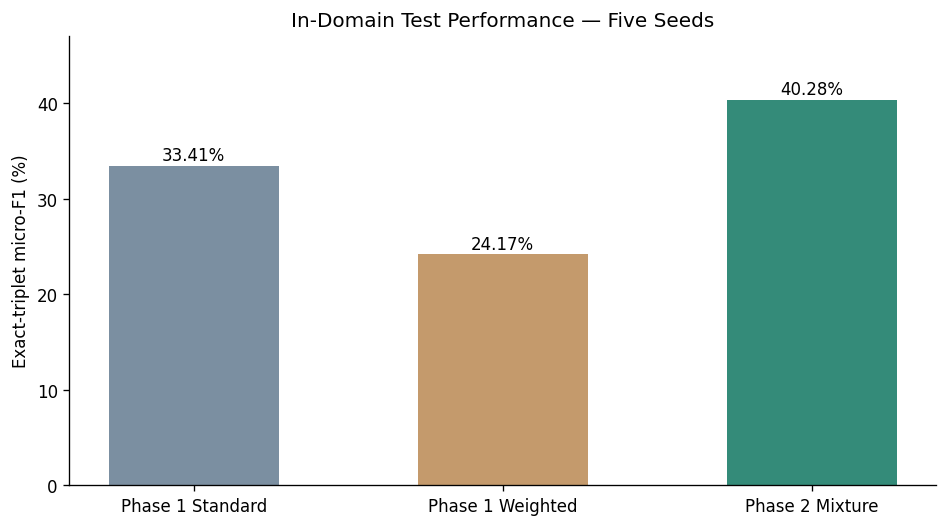

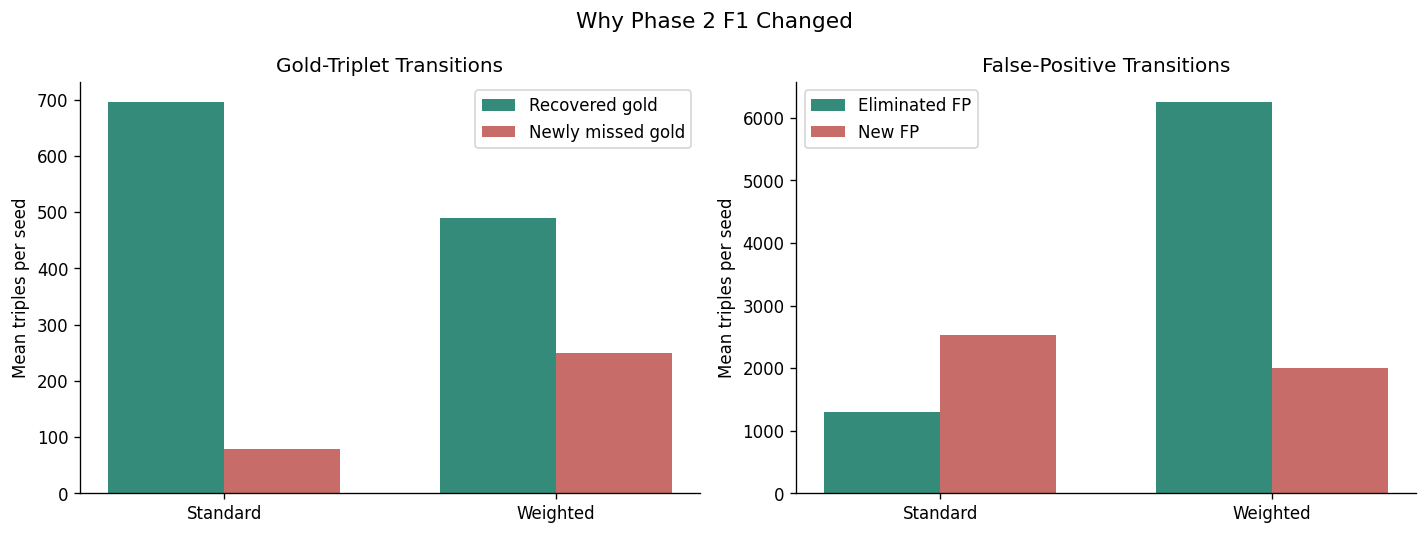

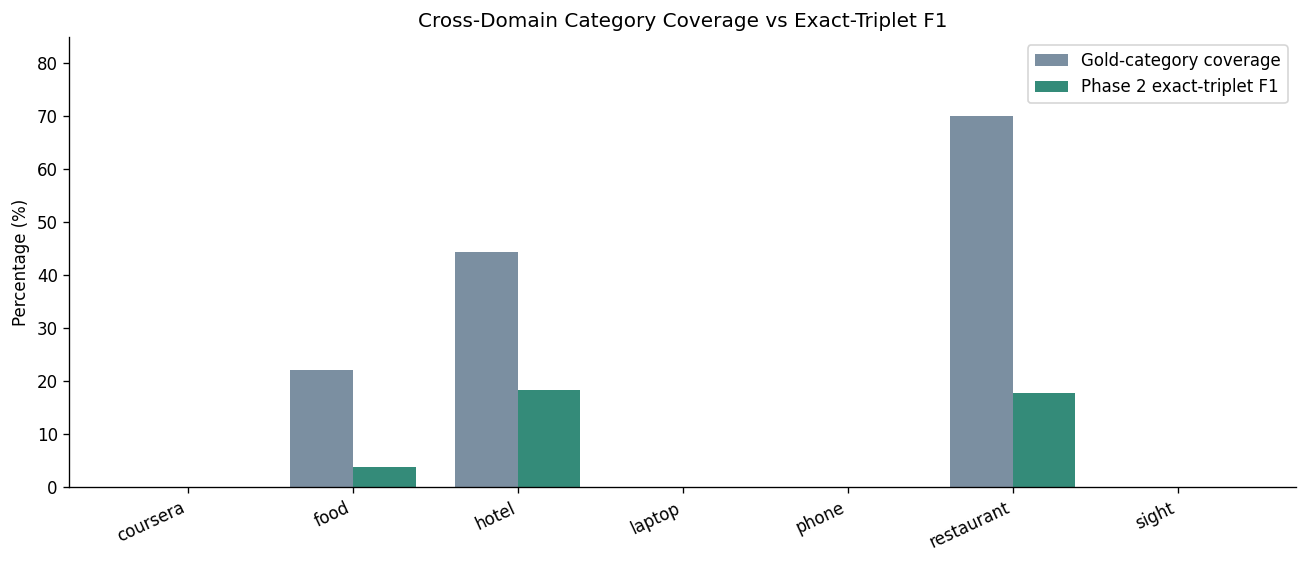

In [20]:
# Final evaluation and error-analysis visualisations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Figure 1: In-domain exact-triplet F1
# Five-seed means independently validated in earlier cells

models = ["Phase 1 Standard", "Phase 1 Weighted", "Phase 2 Mixture"]
f1_scores = [
    results.loc[results["Phase 1 baseline"] == "standard", "Baseline F1"].iloc[0],
    results.loc[results["Phase 1 baseline"] == "weighted", "Baseline F1"].iloc[0],
    results.loc[results["Phase 1 baseline"] == "standard", "Phase 2 F1"].iloc[0]
]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    models,
    f1_scores,
    color=["#7B8FA1", "#C49A6C", "#348B79"],
    width=0.55
)

for bar, value in zip(bars, f1_scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.6,
        f"{value:.2f}%",
        ha="center",
        fontsize=10
    )

ax.set_ylabel("Exact-triplet micro-F1 (%)")
ax.set_title("In-Domain Test Performance — Five Seeds")
ax.set_ylim(0, 47)
plt.tight_layout()
plt.show()


# Figure 2: Error transitions from Phase 1 to Phase 2
# Mean counts per seed, from validated Cells 5–7

transition_data = pd.DataFrame({
    "Baseline": ["Standard", "Weighted"],
    "Recovered gold": [transition_summary.loc[m, ("recovered", "mean")] for m in ["standard", "weighted"]],
    "Newly missed gold": [transition_summary.loc[m, ("new_miss", "mean")] for m in ["standard", "weighted"]],
    "Eliminated false positives": [fp_summary.loc[m, ("eliminated_fp", "mean")] for m in ["standard", "weighted"]],
    "New false positives": [fp_summary.loc[m, ("new_fp", "mean")] for m in ["standard", "weighted"]]
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

x = np.arange(2)
width = 0.35

axes[0].bar(
    x - width / 2,
    transition_data["Recovered gold"],
    width,
    label="Recovered gold",
    color="#348B79"
)

axes[0].bar(
    x + width / 2,
    transition_data["Newly missed gold"],
    width,
    label="Newly missed gold",
    color="#C76C68"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(transition_data["Baseline"])
axes[0].set_ylabel("Mean triples per seed")
axes[0].set_title("Gold-Triplet Transitions")
axes[0].legend()

axes[1].bar(
    x - width / 2,
    transition_data["Eliminated false positives"],
    width,
    label="Eliminated FP",
    color="#348B79"
)

axes[1].bar(
    x + width / 2,
    transition_data["New false positives"],
    width,
    label="New FP",
    color="#C76C68"
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(transition_data["Baseline"])
axes[1].set_ylabel("Mean triples per seed")
axes[1].set_title("False-Positive Transitions")
axes[1].legend()

fig.suptitle("Why Phase 2 F1 Changed", fontsize=13)
plt.tight_layout()
plt.show()


# Figure 3: Cross-domain category coverage and exact F1
# Use independently validated Cell 16 and Cell 15 data

domain_order = list(DOMAINS)

coverage_pct = (
    100 * vocabulary_df.groupby("domain")["covered_gold"].first() /
    lodo_predictions_df.groupby("domain")["gold"].first()
)

coverage_pct = coverage_pct.reindex(domain_order)

lodo_f1 = (
    lodo_predictions_df.groupby("domain")["f1"]
    .mean()
    .reindex(domain_order) * 100
)

x = np.arange(len(domain_order))
width = 0.38

fig, ax = plt.subplots(figsize=(11, 4.8))

ax.bar(
    x - width / 2,
    coverage_pct,
    width,
    label="Gold-category coverage",
    color="#7B8FA1"
)

ax.bar(
    x + width / 2,
    lodo_f1,
    width,
    label="Phase 2 exact-triplet F1",
    color="#348B79"
)

ax.set_xticks(x)
ax.set_xticklabels(domain_order, rotation=25, ha="right")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 85)
ax.set_title("Cross-Domain Category Coverage vs Exact-Triplet F1")
ax.legend()

plt.tight_layout()
plt.show()

### Key Findings and Practical Implications

1. **In-domain improvement:** Phase 2 achieved **40.28% F1**, versus 33.41% (standard) and 24.17% (weighted). Higher recall drove the improvement despite additional false positives relative to standard BERT.
2. **Error mechanisms:** Term extraction remains a major weakness; category and sentiment errors also prevent exact-triplet matches.
3. **Cross-domain limitation:** Four of seven domains achieved zero exact-triplet F1. **83.77%** of LODO gold triples used categories absent from the reference source vocabulary; no true positives were observed for these triples. Covered categories also exhibited errors.
4. **Rarity and NULL:** Rare categories had substantially lower in-domain recall than frequent categories. Exploratory NULL experiments achieved zero NULL F1.
5. **Practical priorities:** Improve transferable category coverage and aspect-span extraction, reduce false positives, and evaluate performance by domain, component and category frequency.